In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import datetime

In [2]:
df = pd.read_csv("../data/raw/T_ONTIME_REPORTING.csv")

Una vez importadas las librerias y leido el csv, debemos realizar una exploracion basica de los datos. 
El tema aca que luego lo vamos a pasar a goolge.colab y ahi lo deberiamos dejar mejor. Esto es la base inicial.
El csv original es mucho mas grande que el que luego vamos a purificar porque hay muchas variables redundantes, eso es algo a tener en cuenta para el trabajo. 

In [3]:
print(df["DEP_DEL15"].unique())

[ 0.  1. nan]


In [4]:
# Tipos de datos  por columna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 609743 entries, 0 to 609742
Data columns (total 27 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   DAY_OF_MONTH           609743 non-null  int64  
 1   DAY_OF_WEEK            609743 non-null  int64  
 2   FL_DATE                609743 non-null  str    
 3   OP_UNIQUE_CARRIER      609743 non-null  str    
 4   TAIL_NUM               608342 non-null  str    
 5   OP_CARRIER_FL_NUM      609743 non-null  int64  
 6   ORIGIN_AIRPORT_ID      609743 non-null  int64  
 7   ORIGIN_AIRPORT_SEQ_ID  609743 non-null  int64  
 8   ORIGIN_CITY_MARKET_ID  609743 non-null  int64  
 9   ORIGIN                 609743 non-null  str    
 10  ORIGIN_CITY_NAME       609743 non-null  str    
 11  ORIGIN_STATE_ABR       609743 non-null  str    
 12  DEST_AIRPORT_ID        609743 non-null  int64  
 13  DEST_AIRPORT_SEQ_ID    609743 non-null  int64  
 14  DEST_CITY_MARKET_ID    609743 non-null  int64  

In [3]:
# Shape y memoria -> HAY 609.743 Vuelos en el mes de mayo del 2024
print("Shape:", df.shape)

Shape: (609743, 27)


Eliminamos vuelos cancelados

In [5]:
# 1. Chequeamos si hay registros nulos en la variable objetivo )dep_del15).
# Eso es un indicador si el vuelo esta cancelado o no
nulos_target = df['DEP_DEL15'].isna().sum()
print(f"Valores nulos en DEP_DEL15: {nulos_target}")

Valores nulos en DEP_DEL15: 7976


In [6]:
# 2. Chequeamos los valores válidos presentes. .value cuenta la frecuencia de cada valor único en esa columna
print(df['DEP_DEL15'].value_counts(dropna=False))

DEP_DEL15
0.0    447354
1.0    154413
NaN      7976
Name: count, dtype: int64


In [7]:
# Filtramos los nulos de DEP_DEL15 para eliminar los vuelos cancelados
df_validos = df.dropna(subset=['DEP_DEL15']).copy()
df_validos['DEP_DEL15'] = df_validos['DEP_DEL15'].astype(int)

print(f"Observaciones antes del filtrado: {len(df):,}")
print(f"Observaciones del universo válido: {len(df_validos):,}")

Observaciones antes del filtrado: 609,743
Observaciones del universo válido: 601,767


Ahora vamos a purificar el dataframe de variables redundantes

In [8]:
#Definición de variables redundantes a eliminar

cols_redundantes = [
    # Varianza cero
    'FLIGHTS',
    # Redundancias en Origen
    'ORIGIN_AIRPORT_ID',
    'ORIGIN_AIRPORT_SEQ_ID',
    'ORIGIN_CITY_NAME',
    # Redundancias en Destino 
    'DEST_AIRPORT_ID',
    'DEST_AIRPORT_SEQ_ID',
    'DEST_CITY_NAME',
    'DEST_STATE_NM',
    # Redundancia operacional / colinealidad con DISTANCE
    'DISTANCE_GROUP'
]

In [9]:
# Eliminación de variables redundantes
df_processed = df_validos.drop(columns=cols_redundantes)
print(
    f"Se eliminaron {len(cols_redundantes)} columnas redundantes con éxito.\n"
)

Se eliminaron 9 columnas redundantes con éxito.



In [10]:
df_processed.head()

,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_CITY_MARKET_ID,ORIGIN,ORIGIN_STATE_ABR,DEST_CITY_MARKET_ID,DEST,DEST_STATE_ABR,CRS_DEP_TIME,DEP_DEL15,DEP_TIME_BLK,CRS_ARR_TIME,CRS_ELAPSED_TIME,DISTANCE
0,1,3,5/1/2024 12:00:00 AM,9E,N131EV,4934,31650,MSP,MN,30424,CWA,WI,1950,0,1900-1959,2050,60.0,175.0
1,1,3,5/1/2024 12:00:00 AM,9E,N131EV,5047,31650,MSP,MN,30198,PIT,PA,1245,0,1200-1259,1552,127.0,726.0
2,1,3,5/1/2024 12:00:00 AM,9E,N131EV,5047,30198,PIT,PA,31650,MSP,MN,1632,0,1600-1659,1755,143.0,726.0
3,1,3,5/1/2024 12:00:00 AM,9E,N131EV,5130,33105,CVG,KY,31650,MSP,MN,1040,0,1000-1059,1142,122.0,596.0
4,1,3,5/1/2024 12:00:00 AM,9E,N131EV,5167,31295,DTW,MI,33105,CVG,KY,840,0,0800-0859,952,72.0,229.0


In [11]:
df_processed.info()


<class 'pandas.DataFrame'>
Index: 601767 entries, 0 to 609742
Data columns (total 18 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   DAY_OF_MONTH           601767 non-null  int64  
 1   DAY_OF_WEEK            601767 non-null  int64  
 2   FL_DATE                601767 non-null  str    
 3   OP_UNIQUE_CARRIER      601767 non-null  str    
 4   TAIL_NUM               601767 non-null  str    
 5   OP_CARRIER_FL_NUM      601767 non-null  int64  
 6   ORIGIN_CITY_MARKET_ID  601767 non-null  int64  
 7   ORIGIN                 601767 non-null  str    
 8   ORIGIN_STATE_ABR       601767 non-null  str    
 9   DEST_CITY_MARKET_ID    601767 non-null  int64  
 10  DEST                   601767 non-null  str    
 11  DEST_STATE_ABR         601767 non-null  str    
 12  CRS_DEP_TIME           601767 non-null  int64  
 13  DEP_DEL15              601767 non-null  int64  
 14  DEP_TIME_BLK           601767 non-null  str    
 15 

FIN DE LA PURIFICACION DEL DATA SET

Inicio de CASTEO DE DATOS y codigos para responder la consigna de:
1. Variables derivadas pertinentes (por ejemplo, hora o franja horaria de salida). 
2. Codificación (encoding) y demás transformaciones necesarias. Justificar si corresponde normalizar según los modelos utilizados. 

In [12]:
#Casteo de datos
# Asegurar que los IDs de mercado y números de vuelo no se lean como valores numéricos
df_processed['ORIGIN_CITY_MARKET_ID'] = df_processed[
    'ORIGIN_CITY_MARKET_ID'
].astype(str)
df_processed['DEST_CITY_MARKET_ID'] = df_processed[
    'DEST_CITY_MARKET_ID'
].astype(str)

if 'OP_CARRIER_FL_NUM' in df_processed.columns:
  df_processed['OP_CARRIER_FL_NUM'] = df_processed[
      'OP_CARRIER_FL_NUM'
  ].astype(str)

print(f"Dimensiones finales procesadas: {df_processed.shape}")


Dimensiones finales procesadas: (601767, 18)


In [13]:
df_processed.info()
#Con esto, ya tenemos un dataset limpio y listo para el análisis exploratorio de datos (EDA) y la modelización. 
#DEBEMOS CHEQUEAR/MEJORAR para responder mejor la consigna de {" Identificación de la unidad de observación y de las variables"}

<class 'pandas.DataFrame'>
Index: 601767 entries, 0 to 609742
Data columns (total 18 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   DAY_OF_MONTH           601767 non-null  int64  
 1   DAY_OF_WEEK            601767 non-null  int64  
 2   FL_DATE                601767 non-null  str    
 3   OP_UNIQUE_CARRIER      601767 non-null  str    
 4   TAIL_NUM               601767 non-null  str    
 5   OP_CARRIER_FL_NUM      601767 non-null  str    
 6   ORIGIN_CITY_MARKET_ID  601767 non-null  str    
 7   ORIGIN                 601767 non-null  str    
 8   ORIGIN_STATE_ABR       601767 non-null  str    
 9   DEST_CITY_MARKET_ID    601767 non-null  str    
 10  DEST                   601767 non-null  str    
 11  DEST_STATE_ABR         601767 non-null  str    
 12  CRS_DEP_TIME           601767 non-null  int64  
 13  DEP_DEL15              601767 non-null  int64  
 14  DEP_TIME_BLK           601767 non-null  str    
 15 

-----------------FIN CASTEO------------
Inicio de proceasamiento de variables
consigna -> Variables derivadas pertinentes (por ejemplo, hora o franja horaria de salida). 

In [14]:
#Es necesario analizar como manejar las variables de tiempo que están en formato HHMM,
# para que sean más fáciles de interpretar y potenciar el resultado de los arboles
df_processed[['CRS_DEP_TIME', 'CRS_ARR_TIME','CRS_ELAPSED_TIME' ]]


,CRS_DEP_TIME,CRS_ARR_TIME,CRS_ELAPSED_TIME
0,1950,2050,60.0
1,1245,1552,127.0
2,1632,1755,143.0
3,1040,1142,122.0
4,840,952,72.0
...,...,...,...
609738,700,859,119.0
609739,1457,1605,68.0
609740,1257,1408,71.0
609741,950,1213,143.0


In [15]:
# 1. Extraemos la hora programada (0 a 23) diviendo por 100 (la hora está en formato HHMM)
df_processed['CRS_DEP_HOUR'] = df_processed['CRS_DEP_TIME'] // 100
df_processed['CRS_ARR_HOUR'] = df_processed['CRS_ARR_TIME'] // 100

In [16]:
df_processed[['CRS_DEP_TIME', 'CRS_DEP_HOUR', 'CRS_ARR_TIME', 'CRS_ARR_HOUR']].head()


,CRS_DEP_TIME,CRS_DEP_HOUR,CRS_ARR_TIME,CRS_ARR_HOUR
0,1950,19,2050,20
1,1245,12,1552,15
2,1632,16,1755,17
3,1040,10,1142,11
4,840,8,952,9


In [17]:
# 2. Definimos nuevas franjas horarias operativas para la salida y facilitar el análisis de la variable objetivo.
# Intervalos: [0, 5], [6, 11], [12, 17], [18, 23]
bins = [-1, 5, 11, 17, 23]
labels = ['Madrugada', 'Mañana', 'Tarde', 'Noche']

df_processed['DEP_TIME_OF_DAY'] = pd.cut(
    df_processed['CRS_DEP_HOUR'], 
    bins=bins, 
    labels=labels
)

In [18]:
# 1. Verificar rangos de las nuevas columnas numéricas
print("Rangos de horas extraídas:")
print(df_processed[['CRS_DEP_HOUR', 'CRS_ARR_HOUR']].describe().T[['min', 'max', 'mean']])

# 2. Verificar distribución de vuelos por franja horaria
print("\nDistribución de vuelos por franja horaria:")
print(df_processed['DEP_TIME_OF_DAY'].value_counts(dropna=False))

Rangos de horas extraídas:
              min   max       mean
CRS_DEP_HOUR  0.0  23.0  13.032528
CRS_ARR_HOUR  0.0  23.0  14.631296

Distribución de vuelos por franja horaria:
DEP_TIME_OF_DAY
Mañana       233002
Tarde        212265
Noche        138389
Madrugada     18111
Name: count, dtype: int64


In [19]:
# 1. Agrupamos los datos por hora programada de salida (0 a 23 horas)
# Se calcula el volumen de vuelos y el porcentaje de retrasos para cada hora
hourly_delays = df_processed.groupby('CRS_DEP_HOUR')['DEP_DEL15'].agg(
    total_vuelos='count',  # Cantidad total de vuelos programados en esa hora
    tasa_demora='mean'     # Proporción de vuelos retrasados
)

print("Tasa de demora por hora programada (CRS_DEP_HOUR):")
print(hourly_delays)


Tasa de demora por hora programada (CRS_DEP_HOUR):
              total_vuelos  tasa_demora
CRS_DEP_HOUR                           
0                     1155     0.301299
1                      386     0.248705
2                      139     0.251799
3                       78     0.166667
4                       52     0.134615
5                    16301     0.086989
6                    42376     0.086110
7                    42158     0.109991
8                    41108     0.138002
9                    32740     0.163897
10                   38590     0.199274
11                   36030     0.219400
12                   36177     0.249274
13                   36103     0.268842
14                   32861     0.303643
15                   35198     0.318541
16                   34038     0.347053
17                   37888     0.349240
18                   36800     0.370734
19                   34651     0.393235
20                   26550     0.407194
21                   20804   

In [20]:
# 2. Tasa de demora según la franja horaria operativa. Misma lógica que la anterior, ç
# pero agrupando por la nueva variable categórica DEP_TIME_OF_DAY
time_of_day_delays = df_processed.groupby('DEP_TIME_OF_DAY', observed=True)['DEP_DEL15'].agg(
    total_vuelos='count',
    tasa_demora='mean'
)
print("\nTasa de demora por franja horaria (DEP_TIME_OF_DAY):")
print(time_of_day_delays)


Tasa de demora por franja horaria (DEP_TIME_OF_DAY):
                 total_vuelos  tasa_demora
DEP_TIME_OF_DAY                           
Madrugada               18111     0.105847
Mañana                 233002     0.149870
Tarde                  212265     0.306028
Noche                  138389     0.380211


C:\Users\vagui\AppData\Local\Temp\ipykernel_7248\1527727248.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


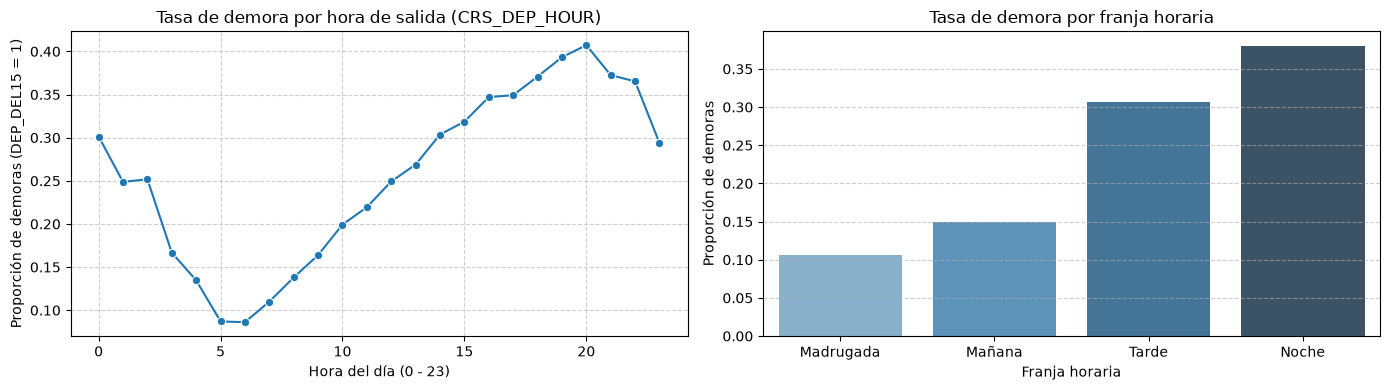

In [21]:
#Visualización grafica de los indicadores obtenidos. 
fig, axes = plt.subplots(1, 2, figsize=(14, 4)) #este comando prepara el terreno para  poner dos gráficos distintos, uno al lado del otro

# Gráfico 1: Tasa por hora entera
sns.lineplot(
    data=hourly_delays.reset_index(), 
    x='CRS_DEP_HOUR', 
    y='tasa_demora', 
    marker='o', 
    ax=axes[0]
)
axes[0].set_title('Tasa de demora por hora de salida (CRS_DEP_HOUR)')
axes[0].set_xlabel('Hora del día (0 - 23)')
axes[0].set_ylabel('Proporción de demoras (DEP_DEL15 = 1)')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Gráfico 2: Tasa por franja operativa
sns.barplot(
    data=time_of_day_delays.reset_index(), 
    x='DEP_TIME_OF_DAY', 
    y='tasa_demora', 
    palette='Blues_d', 
    ax=axes[1]
)
axes[1].set_title('Tasa de demora por franja horaria')
axes[1].set_xlabel('Franja horaria')
axes[1].set_ylabel('Proporción de demoras')
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [22]:
# Visto que fue exitoso la creacion de la variable categórica DEP_TIME_OF_DAY y la transformación de CRS_DEP_TIME y 
# CRS_ARR_TIME a nuevas variables, podemos eliminar las variable originales  para simplificar el dataset.

df_processed = df_processed.drop(columns=['CRS_DEP_TIME', 'CRS_ARR_TIME'])


In [20]:
df_processed.info()

<class 'pandas.DataFrame'>
Index: 601767 entries, 0 to 609742
Data columns (total 19 columns):
 #   Column                 Non-Null Count   Dtype   
---  ------                 --------------   -----   
 0   DAY_OF_MONTH           601767 non-null  int64   
 1   DAY_OF_WEEK            601767 non-null  int64   
 2   FL_DATE                601767 non-null  str     
 3   OP_UNIQUE_CARRIER      601767 non-null  str     
 4   TAIL_NUM               601767 non-null  str     
 5   OP_CARRIER_FL_NUM      601767 non-null  str     
 6   ORIGIN_CITY_MARKET_ID  601767 non-null  str     
 7   ORIGIN                 601767 non-null  str     
 8   ORIGIN_STATE_ABR       601767 non-null  str     
 9   DEST_CITY_MARKET_ID    601767 non-null  str     
 10  DEST                   601767 non-null  str     
 11  DEST_STATE_ABR         601767 non-null  str     
 12  DEP_DEL15              601767 non-null  int64   
 13  DEP_TIME_BLK           601767 non-null  str     
 14  CRS_ELAPSED_TIME       601767 non-nu

--- AUDITORÍA DE TASAS DIARIAS (DAY_OF_MONTH) ---
       total_vuelos  tasa_demora
count       31.0000      31.0000
mean     19411.8387       0.2555
std       1042.3215       0.0446
min      17216.0000       0.1442
25%      18949.0000       0.2289
50%      19872.0000       0.2533
75%      20259.5000       0.2823
max      20572.0000       0.3466


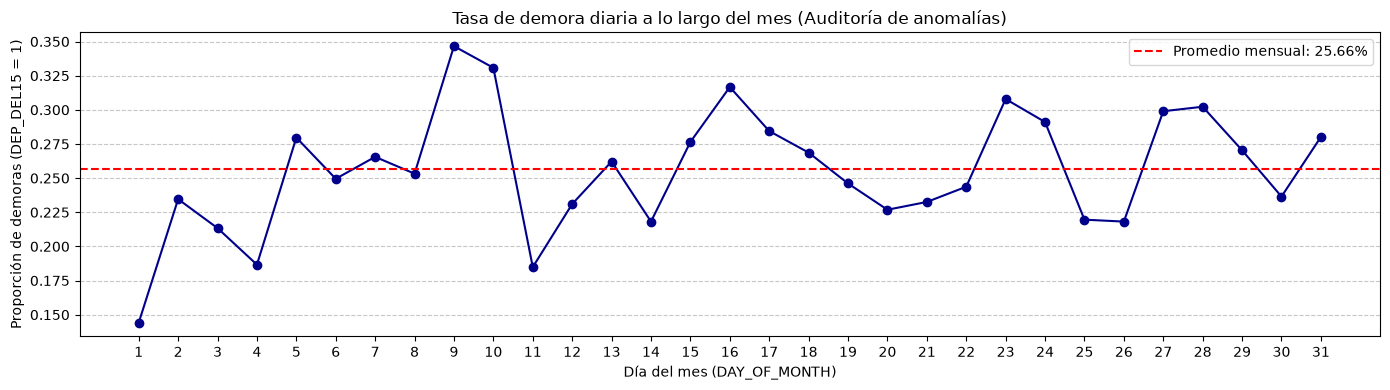

In [23]:
# DAY_OF_MONTH, al tratarse solamente de mayo, no generaliza como un ciclo mensual general, 
# y esta atada a eventos específicos de ese mes particular, con el riesgo de generar un sobre ajuste en el modelo.
# Sin embargo, es util para detectar días atípicos y evaluar su concecuencia en la demora o no de los vuelos.

daily_delay = df_processed.groupby('DAY_OF_MONTH')['DEP_DEL15'].agg(
    total_vuelos='count',
    tasa_demora='mean'
)

print("--- AUDITORÍA DE TASAS DIARIAS (DAY_OF_MONTH) ---")
print(daily_delay.describe().round(4))

# Visualización temporal del comportamiento mensual
plt.figure(figsize=(14, 4))
plt.plot(daily_delay.index, daily_delay['tasa_demora'], marker='o', color='darkblue', linewidth=1.5)
plt.axhline(df_processed['DEP_DEL15'].mean(), color='red', linestyle='--', label=f'Promedio mensual: {df_processed["DEP_DEL15"].mean():.2%}')
plt.title('Tasa de demora diaria a lo largo del mes (Auditoría de anomalías)')
plt.xlabel('Día del mes (DAY_OF_MONTH)')
plt.ylabel('Proporción de demoras (DEP_DEL15 = 1)')
plt.xticks(range(1, daily_delay.index.max() + 1))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
# ONE-HOT ENCODING DE DAY_OF_WEEK. En base al estándar BTS: 1 = Lunes (Monday) a 7 = Domingo (Sunday)
dias_map = {
    1: 'Lunes', 
    2: 'Martes', 
    3: 'Miercoles', 
    4: 'Jueves', 
    5: 'Viernes', 
    6: 'Sabado', 
    7: 'Domingo'
}
df_processed['DAY_OF_WEEK_NAME'] = df_processed['DAY_OF_WEEK'].map(dias_map)

# Tasa empírica por día de la semana
weekday_delays = df_processed.groupby('DAY_OF_WEEK_NAME', observed=False)['DEP_DEL15'].agg(
    total_vuelos='count',
    tasa_demora='mean'
).reindex(dias_map.values())

print("\n--- TASA DE DEMORA POR DÍA DE LA SEMANA ---")
print(weekday_delays)

# One-Hot Encoding: Generar columnas dummy binarias (0 / 1)
# Se usa prefijo 'DOW' para trazabilidad limpia
df_dow_dummies = pd.get_dummies(
    df_processed['DAY_OF_WEEK_NAME'], 
    prefix='DOW', 
    dtype=int
)

# Incorporar las dummies al DataFrame
df_processed = pd.concat([df_processed, df_dow_dummies], axis=1)

print("\nColumnas generadas mediante One-Hot Encoding:")
print([col for col in df_processed.columns if col.startswith('DOW_')])


--- TASA DE DEMORA POR DÍA DE LA SEMANA ---
                  total_vuelos  tasa_demora
DAY_OF_WEEK_NAME                           
Lunes                    81110     0.259290
Martes                   75405     0.254201
Miercoles                95306     0.237614
Jueves                  100626     0.288663
Viernes                 101754     0.280018
Sabado                   69239     0.215096
Domingo                  78327     0.244296

Columnas generadas mediante One-Hot Encoding:
['DOW_Domingo', 'DOW_Jueves', 'DOW_Lunes', 'DOW_Martes', 'DOW_Miercoles', 'DOW_Sabado', 'DOW_Viernes']


FIN DE ONE HOT ENCODING y otras:

Comienzo de deteccion de outliers y datos atipicos

In [26]:
df_processed.info()

<class 'pandas.DataFrame'>
Index: 601767 entries, 0 to 609742
Data columns (total 28 columns):
 #   Column                 Non-Null Count   Dtype   
---  ------                 --------------   -----   
 0   DAY_OF_MONTH           601767 non-null  int64   
 1   DAY_OF_WEEK            601767 non-null  int64   
 2   FL_DATE                601767 non-null  str     
 3   OP_UNIQUE_CARRIER      601767 non-null  str     
 4   TAIL_NUM               601767 non-null  str     
 5   OP_CARRIER_FL_NUM      601767 non-null  str     
 6   ORIGIN_CITY_MARKET_ID  601767 non-null  str     
 7   ORIGIN                 601767 non-null  str     
 8   ORIGIN_STATE_ABR       601767 non-null  str     
 9   DEST_CITY_MARKET_ID    601767 non-null  str     
 10  DEST                   601767 non-null  str     
 11  DEST_STATE_ABR         601767 non-null  str     
 12  DEP_DEL15              601767 non-null  int64   
 13  DEP_TIME_BLK           601767 non-null  str     
 14  CRS_ELAPSED_TIME       601767 non-nu

REVISION DE DATOS FALTANTES:
Se busca responder la consigna ->
 Revisión de faltantes, duplicados, inconsistencias y valores atípicos. Justificar su tratamiento. 

In [25]:
# Objetivo: Confirmar ausencia de nulos .
nulos_por_columna = df_processed.isnull().sum()
total_nulos = nulos_por_columna.sum()

print("=== 1. AUDITORÍA DE VALORES FALTANTES ===")
print(f"Total de celdas con valores faltantes: {total_nulos}")
if total_nulos > 0:
    print(nulos_por_columna[nulos_por_columna > 0])
else:
    print(
        "No se registran valores nulos: el universo quedó acotado a vuelos válidos."
    )

=== 1. AUDITORÍA DE VALORES FALTANTES ===
Total de celdas con valores faltantes: 0
No se registran valores nulos: el universo quedó acotado a vuelos válidos.


In [26]:
# Objetivo: Detectar filas idénticas y evaluar unicidad de la entidad vuelo.
duplicados_totales = df_processed.duplicated().sum()

# Clave operativa de negocio
clave_vuelo = [
    "FL_DATE",
    "OP_UNIQUE_CARRIER",
    "OP_CARRIER_FL_NUM",
    "ORIGIN",
    "DEST",
    "DEP_TIME_BLK",
]
duplicados_clave = df_processed.duplicated(subset=clave_vuelo).sum()

print("\n=== 2. AUDITORÍA DE DUPLICADOS ===")
print(f"Duplicados exactos (todas las columnas): {duplicados_totales}")
print(f"Duplicados por clave operativa de vuelo: {duplicados_clave}")

# Tratamiento: remoción en caso de existir duplicados exactos
if duplicados_totales > 0:
    df_processed = df_processed.drop_duplicates().copy()
    print(
        f"Filas retenidas tras eliminar duplicados: {df_processed.shape[0]}"
    )


=== 2. AUDITORÍA DE DUPLICADOS ===
Duplicados exactos (todas las columnas): 0
Duplicados por clave operativa de vuelo: 0


In [27]:
# 3. DIAGNÓSTICO DE VALORES ATÍPICOS (OUTLIERS)
# Objetivo: Identificar colas mediante IQR en variables continuas y auditar plausibilidad.
variables_continuas = ["DISTANCE", "CRS_ELAPSED_TIME"]

print("\n=== 3. AUDITORÍA DE VALORES ATÍPICOS (IQR) ===")
for col in variables_continuas:
    q1 = df_processed[col].quantile(0.25)
    q3 = df_processed[col].quantile(0.75)
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr

    outliers = df_processed[
        (df_processed[col] < limite_inf) | (df_processed[col] > limite_sup)
    ]
    pct_outliers = (len(outliers) / len(df_processed)) * 100

    print(f"\nVariable: {col}")
    print(
        f"  Límites IQR: [{limite_inf:.1f}, {limite_sup:.1f}] | Min real:"
        f" {df_processed[col].min()} | Max real: {df_processed[col].max()}"
    )
    print(f"  Cantidad de registros fuera de límites: {len(outliers)}")
    print(f"  Proporción sobre el total: {pct_outliers:.2f}%")

# Verificación de plausibilidad en los valores más extremos de distancia (rutas lejanas)
print("\nTop 3 vuelos con mayor distancia (verificación de plausibilidad):")
print(
    df_processed[["ORIGIN", "DEST", "DISTANCE", "CRS_ELAPSED_TIME"]]
    .drop_duplicates(subset=["ORIGIN", "DEST"])
    .nlargest(3, "DISTANCE")
)


=== 3. AUDITORÍA DE VALORES ATÍPICOS (IQR) ===

Variable: DISTANCE
  Límites IQR: [-595.5, 2064.5] | Min real: 31.0 | Max real: 5095.0
  Cantidad de registros fuera de límites: 36572
  Proporción sobre el total: 6.08%

Variable: CRS_ELAPSED_TIME
  Límites IQR: [-32.5, 299.5] | Min real: 22.0 | Max real: 670.0
  Cantidad de registros fuera de límites: 32217
  Proporción sobre el total: 5.35%

Top 3 vuelos con mayor distancia (verificación de plausibilidad):
      ORIGIN DEST  DISTANCE  CRS_ELAPSED_TIME
8017     HNL  BOS    5095.0             585.0
27852    BOS  HNL    5095.0             670.0
4851     HNL  JFK    4983.0             583.0


HNL Es el codigo IATA del aeropuerto de Hawai, lo cual no es un outlier en terminos de distancia, sino algo plausbible dentro de la programacion habitual de los vuelos. 

# Distribución de la variable objetivo y posible desbalance entre clases. 
# Exploración de variables cuantitativas y cualitativas y su relación con la demora. 
 

C:\Users\vagui\AppData\Local\Temp\ipykernel_7248\322092116.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


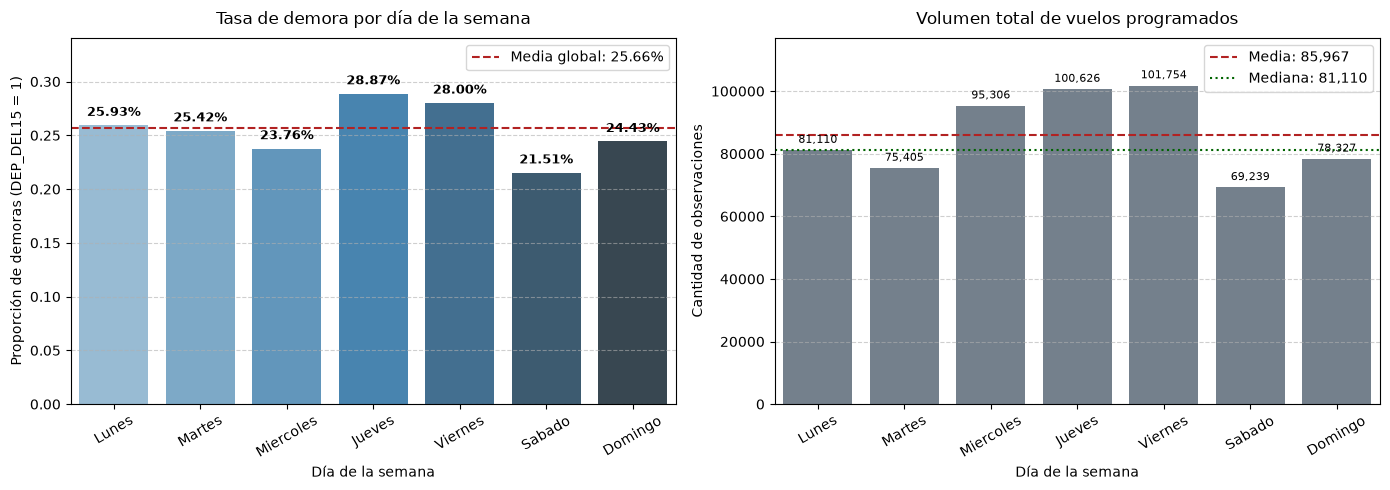

In [36]:
# VISUALIZACIÓN DEL VOLUMEN DE VUELOS Y TASA DE DEMORA POR DÍA DE LA SEMANA

# Orden cronológico estándar de la semana
orden_dias = ['Lunes', 'Martes', 'Miercoles', 'Jueves', 'Viernes', 'Sabado', 'Domingo']
data_plot = weekday_delays.reindex(orden_dias).reset_index()

# Configurar figura con dos paneles alineados
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))


# Panel 1: Tasa de demora condicional (P(DEP_DEL15=1 | Día))

sns.barplot(
    data=data_plot, 
    x='DAY_OF_WEEK_NAME', 
    y='tasa_demora', 
    palette='Blues_d', 
    ax=ax1
)

# Línea de referencia del promedio global del mes 
media_global = df_processed['DEP_DEL15'].mean()
ax1.axhline(media_global, color='firebrick', linestyle='--', linewidth=1.5, label=f'Media global: {media_global:.2%}')

# Etiquetas con porcentaje exacto sobre cada barra
for i, val in enumerate(data_plot['tasa_demora']):
    ax1.text(i, val + 0.006, f'{val:.2%}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax1.set_title('Tasa de demora por día de la semana', fontsize=12, pad=10)
ax1.set_xlabel('Día de la semana', fontsize=10)
ax1.set_ylabel('Proporción de demoras (DEP_DEL15 = 1)', fontsize=10)
ax1.set_ylim(0, max(data_plot['tasa_demora']) * 1.18)
ax1.grid(axis='y', linestyle='--', alpha=0.6)
ax1.tick_params(axis='x', rotation=30)
ax1.legend(loc='upper right')

# Panel 2: Volumen total de vuelos programados (Soporte muestral)

sns.barplot(
    data=data_plot, 
    x='DAY_OF_WEEK_NAME', 
    y='total_vuelos', 
    color='slategray', 
    ax=ax2
)

# Etiquetas con cantidad de vuelos sobre cada barra
for i, val in enumerate(data_plot['total_vuelos']):
    ax2.text(i, val + 1500, f'{val:,}', ha='center', va='bottom', fontsize=8)

# Líneas de media y mediana del volumen de vuelos
media_vuelos = data_plot['total_vuelos'].mean()
mediana_vuelos = data_plot['total_vuelos'].median()
ax2.axhline(media_vuelos, color='firebrick', linestyle='--', linewidth=1.5, label=f'Media: {media_vuelos:,.0f}')
ax2.axhline(mediana_vuelos, color='darkgreen', linestyle=':', linewidth=1.5, label=f'Mediana: {mediana_vuelos:,.0f}')

ax2.set_title('Volumen total de vuelos programados', fontsize=12, pad=10)
ax2.set_xlabel('Día de la semana', fontsize=10)
ax2.set_ylabel('Cantidad de observaciones', fontsize=10)
ax2.set_ylim(0, max(data_plot['total_vuelos']) * 1.15)
ax2.grid(axis='y', linestyle='--', alpha=0.6)
ax2.tick_params(axis='x', rotation=30)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [37]:
# 1. Tabla de frecuencias absolutas y relativas sobre  DEP_DEL15
target_dist = pd.DataFrame({
    'Total_Vuelos': df_processed['DEP_DEL15'].value_counts(),
    'Proporcion': df_processed['DEP_DEL15'].value_counts(normalize=True)
})
print("--- DISTRIBUCIÓN DE DEP_DEL15 ---")
print(target_dist)

# 2. Métricas explícitas de desbalance y baseline (clasificador mayoritario)
n_total = len(df_processed)
n_neg, n_pos = target_dist.loc[0, 'Total_Vuelos'], target_dist.loc[1, 'Total_Vuelos']
p_pos = target_dist.loc[1, 'Proporcion']
imbalance_ratio = n_neg / n_pos #indica cuántas veces es más grande la clase mayoritaria frente a la minoritaria.

print(f"\nTotal observaciones válidas: {n_total:,}")
print(f"Prevalencia de clase positiva (Demora >= 15 min): {p_pos:.2%}")
print(f"Ratio de desbalance (Clase 0 / Clase 1): {imbalance_ratio:.2f}:1")
print(f"Línea de base trivial (Accuracy del Dummy Classifier mayoritario): {1 - p_pos:.2%}")

--- DISTRIBUCIÓN DE DEP_DEL15 ---
           Total_Vuelos  Proporcion
DEP_DEL15                          
0                447354    0.743401
1                154413    0.256599

Total observaciones válidas: 601,767
Prevalencia de clase positiva (Demora >= 15 min): 25.66%
Ratio de desbalance (Clase 0 / Clase 1): 2.90:1
Línea de base trivial (Accuracy del Dummy Classifier mayoritario): 74.34%


C:\Users\vagui\AppData\Local\Temp\ipykernel_7248\1994316923.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=target_dist.index, y=target_dist['Proporcion'], palette='Blues_d')


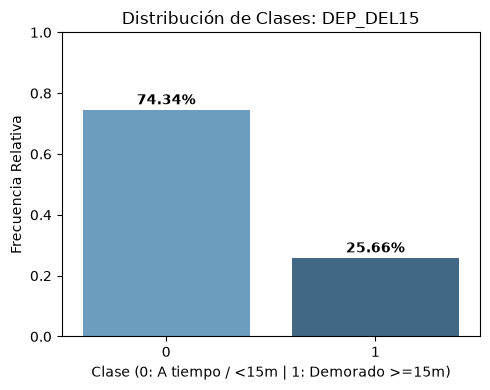

In [38]:
# 3. Histograma de frecuencias relativas
plt.figure(figsize=(5, 4))
sns.barplot(x=target_dist.index, y=target_dist['Proporcion'], palette='Blues_d')
plt.title('Distribución de Clases: DEP_DEL15')
plt.xlabel('Clase (0: A tiempo / <15m | 1: Demorado >=15m)')
plt.ylabel('Frecuencia Relativa')
plt.ylim(0, 1)
for i, val in enumerate(target_dist['Proporcion']):
    plt.text(i, val + 0.02, f'{val:.2%}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

# EXPLORACIÓN  DE VARIABLES CUANTITATIVAS CON DEP_DEL15

In [40]:
# RESUMEN ESTADÍSTICO
num_features = ["CRS_DEP_HOUR", "CRS_ARR_HOUR", "CRS_ELAPSED_TIME", "DISTANCE"]

# Función para calcular IQR de forma directa
def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

# Agregaciones condicionadas al target (0: A tiempo, 1: Demorado)
stats_0 = (
    df_processed[df_processed["DEP_DEL15"] == 0][num_features]
    .agg(["mean", "median", "std", iqr])
    .T
)
stats_1 = (
    df_processed[df_processed["DEP_DEL15"] == 1][num_features]
    .agg(["mean", "median", "std", iqr])
    .T
)

summary_cuant = pd.DataFrame(
    {
        "Media (0)": stats_0["mean"],
        "Media (1)": stats_1["mean"],
        "Dif. Medias (1 - 0)": stats_1["mean"] - stats_0["mean"],
        "Mediana (0)": stats_0["median"],
        "Mediana (1)": stats_1["median"],
        "Dif. Medianas (1 - 0)": stats_1["median"] - stats_0["median"],
        "IQR (0)": stats_0["iqr"],
        "IQR (1)": stats_1["iqr"],
        "Desvío (0)": stats_0["std"],
        "Desvío (1)": stats_1["std"],
    }
).round(2)

print("--- RESUMEN ESTADÍSTICO DE VARIABLES CUANTITATIVAS SEGÚN DEP_DEL15 ---")
print(summary_cuant)

--- RESUMEN ESTADÍSTICO DE VARIABLES CUANTITATIVAS SEGÚN DEP_DEL15 ---
                  Media (0)  Media (1)  Dif. Medias (1 - 0)  Mediana (0)  \
CRS_DEP_HOUR          12.37      14.96                 2.59         12.0   
CRS_ARR_HOUR          14.05      16.32                 2.28         14.0   
CRS_ELAPSED_TIME     145.08     147.47                 2.39        127.0   
DISTANCE             829.08     848.57                19.49        669.0   

                  Mediana (1)  Dif. Medianas (1 - 0)  IQR (0)  IQR (1)  \
CRS_DEP_HOUR             16.0                    4.0      8.0      7.0   
CRS_ARR_HOUR             17.0                    3.0      8.0      7.0   
CRS_ELAPSED_TIME        133.0                    6.0     84.0     83.0   
DISTANCE                722.0                   53.0    664.0    669.0   

                  Desvío (0)  Desvío (1)  
CRS_DEP_HOUR            4.90        4.46  
CRS_ARR_HOUR            5.07        5.20  
CRS_ELAPSED_TIME       72.78       70.47  
DISTA

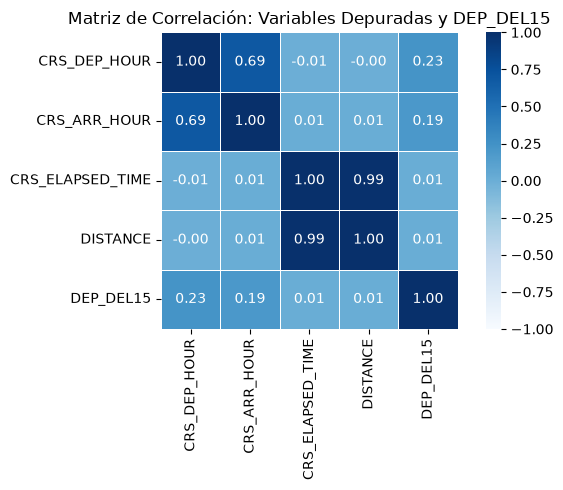

In [42]:
# 3. MATRIZ DE CORRELACIÓN DE PEARSON Y AUDITORÍA DE COLINEALIDAD

corr_matrix = df_processed[num_features + ["DEP_DEL15"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=-1,
    vmax=1,
    cbar=True,
    square=True,
    linewidths=0.5,
)
plt.title("Matriz de Correlación: Variables Depuradas y DEP_DEL15")
plt.tight_layout()
plt.show()

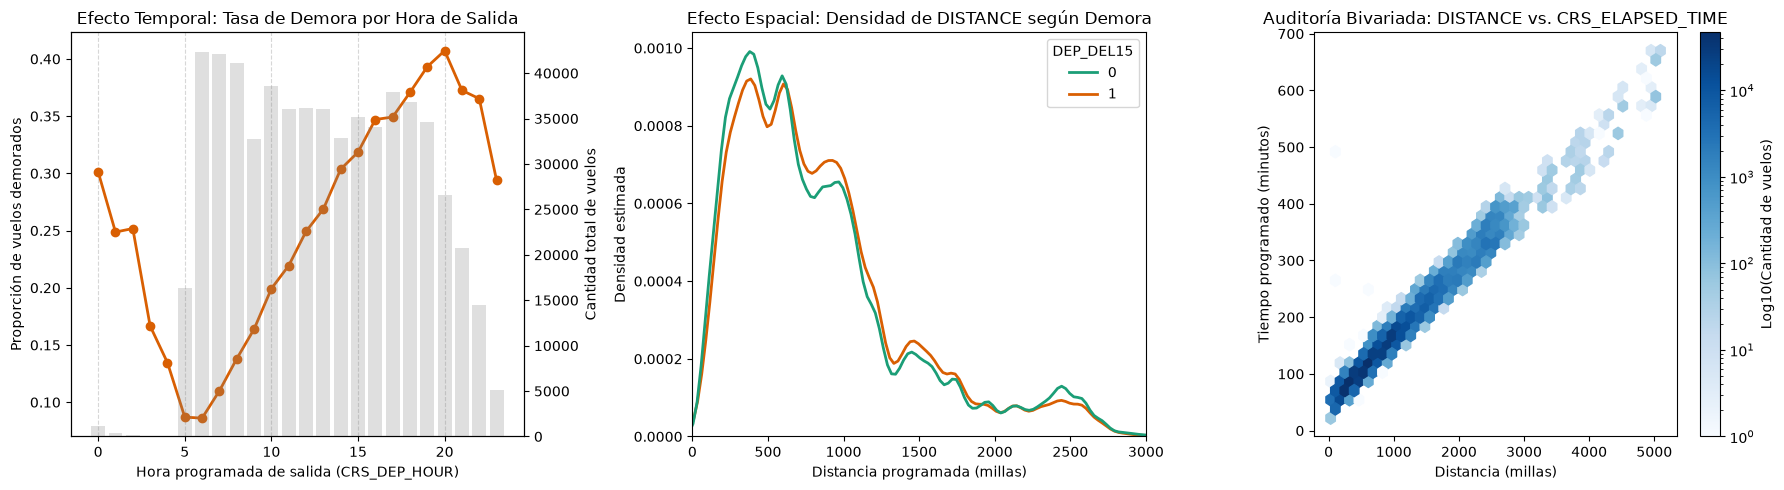

In [44]:
# 4. PANEL VISUAL ANALÍTICO

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel A: Tasa de demora empírica por hora programada de salida
hourly_stats = (
    df_processed.groupby("CRS_DEP_HOUR")["DEP_DEL15"]
    .agg(tasa_demora="mean", volumen="count")
    .reset_index()
)

ax_vol = axes[0].twinx()
ax_vol.bar(
    hourly_stats["CRS_DEP_HOUR"],
    hourly_stats["volumen"],
    alpha=0.25,
    color="gray",
    label="Volumen de vuelos",
)
axes[0].plot(
    hourly_stats["CRS_DEP_HOUR"],
    hourly_stats["tasa_demora"],
    color="#d95f02",
    marker="o",
    linewidth=2,
    label="Tasa de demora",
)
axes[0].set_title("Efecto Temporal: Tasa de Demora por Hora de Salida")
axes[0].set_xlabel("Hora programada de salida (CRS_DEP_HOUR)")
axes[0].set_ylabel("Proporción de vuelos demorados")
ax_vol.set_ylabel("Cantidad total de vuelos")
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

# Panel B: Curvas de densidad (KDE) de Distancia según estado del vuelo
sns.kdeplot(
    data=df_processed,
    x="DISTANCE",
    hue="DEP_DEL15",
    common_norm=False,
    palette={0: "#1b9e77", 1: "#d95f02"},
    ax=axes[1],
    linewidth=2,
)
axes[1].set_title("Efecto Espacial: Densidad de DISTANCE según Demora")
axes[1].set_xlabel("Distancia programada (millas)")
axes[1].set_ylabel("Densidad estimada")
axes[1].set_xlim(0, 3000)  # Foco en el 95% central de la operativa

# Panel C: Relación física bivariada (Hexbin de densidad operacional)
hb = axes[2].hexbin(
    df_processed["DISTANCE"],
    df_processed["CRS_ELAPSED_TIME"],
    gridsize=35,
    cmap="Blues",
    mincnt=1,
    bins="log",
)
fig.colorbar(hb, ax=axes[2], label="Log10(Cantidad de vuelos)")
axes[2].set_title("Auditoría Bivariada: DISTANCE vs. CRS_ELAPSED_TIME")
axes[2].set_xlabel("Distancia (millas)")
axes[2].set_ylabel("Tiempo programado (minutos)")

plt.tight_layout()
plt.show()

# EXPLORACIÓN  DE VARIABLES CUALITATIVAS CON DEP_DEL15

In [49]:
# 0. PARÁMETROS GLOBALES
# ==============================================================================
tasa_base_global = df_processed['DEP_DEL15'].mean()
print(f"Tasa base global de demoras: {tasa_base_global:.4f} ({tasa_base_global*100:.2f}%)")

# ==============================================================================
# 1. TABLA DE CONTINGENCIA Y GRADIENTE POR AEROLÍNEA (OP_UNIQUE_CARRIER)
# ==============================================================================
# A. Tabla de contingencia normalizada por fila (probabilidad condicional)
ct_carrier = pd.crosstab(
    df_processed['OP_UNIQUE_CARRIER'], 
    df_processed['DEP_DEL15'], 
    normalize='index'
)
ct_carrier['Volumen'] = df_processed['OP_UNIQUE_CARRIER'].value_counts()
ct_carrier = ct_carrier.sort_values(by=1, ascending=True)

print("\n--- TABLA DE CONTINGENCIA: AEROLÍNEAS (ORDENADA POR TASA DE DEMORA) ---")
print(ct_carrier.round(4))

Tasa base global de demoras: 0.2566 (25.66%)

--- TABLA DE CONTINGENCIA: AEROLÍNEAS (ORDENADA POR TASA DE DEMORA) ---
DEP_DEL15               0       1  Volumen
OP_UNIQUE_CARRIER                         
YX                 0.8689  0.1311    25281
9E                 0.8506  0.1494    16113
HA                 0.8202  0.1798     6489
OO                 0.8138  0.1862    61262
DL                 0.7980  0.2020    88225
G4                 0.7924  0.2076     9534
AS                 0.7857  0.2143    21155
OH                 0.7570  0.2430    18659
UA                 0.7506  0.2494    63411
B6                 0.7389  0.2611    21145
NK                 0.7247  0.2753    23050
MQ                 0.7042  0.2958    23740
WN                 0.6936  0.3064   121690
F9                 0.6713  0.3287    18183
AA                 0.6508  0.3492    83830


In [50]:
# ==============================================================================
# 2. ALTA CARDINALIDAD: TRATAMIENTO TOP-15 EN AEROPUERTO DE ORIGEN (ORIGIN)
# ==============================================================================
# D. Agrupamiento de niveles minoritarios bajo 'OTROS'
top_15_airports = df_processed['ORIGIN'].value_counts().nlargest(15).index

df_processed['ORIGIN_TOP'] = df_processed['ORIGIN'].apply(
    lambda x: x if x in top_15_airports else 'OTROS'
)

# Tabla de contingencia para orígenes consolidados
ct_origin = pd.crosstab(
    df_processed['ORIGIN_TOP'], 
    df_processed['DEP_DEL15'], 
    normalize='index'
)
ct_origin['Volumen'] = df_processed['ORIGIN_TOP'].value_counts()
ct_origin = ct_origin.sort_values(by=1, ascending=True)

print("\n--- TABLA DE CONTINGENCIA: TOP-15 ORÍGENES + OTROS ---")
print(ct_origin.round(4))


--- TABLA DE CONTINGENCIA: TOP-15 ORÍGENES + OTROS ---
DEP_DEL15        0       1  Volumen
ORIGIN_TOP                         
DTW         0.8061  0.1939    11240
LGA         0.7947  0.2053    13873
BOS         0.7774  0.2226    12573
LAX         0.7758  0.2242    16499
SEA         0.7698  0.2302    14272
EWR         0.7633  0.2367    11210
OTROS       0.7579  0.2421   338920
DCA         0.7566  0.2434    11872
PHX         0.7482  0.2518    16632
ATL         0.7467  0.2533    29703
LAS         0.7331  0.2669    16241
MCO         0.7155  0.2845    13721
DEN         0.7081  0.2919    26167
ORD         0.6936  0.3064    24451
CLT         0.6398  0.3602    18956
DFW         0.6024  0.3976    25437


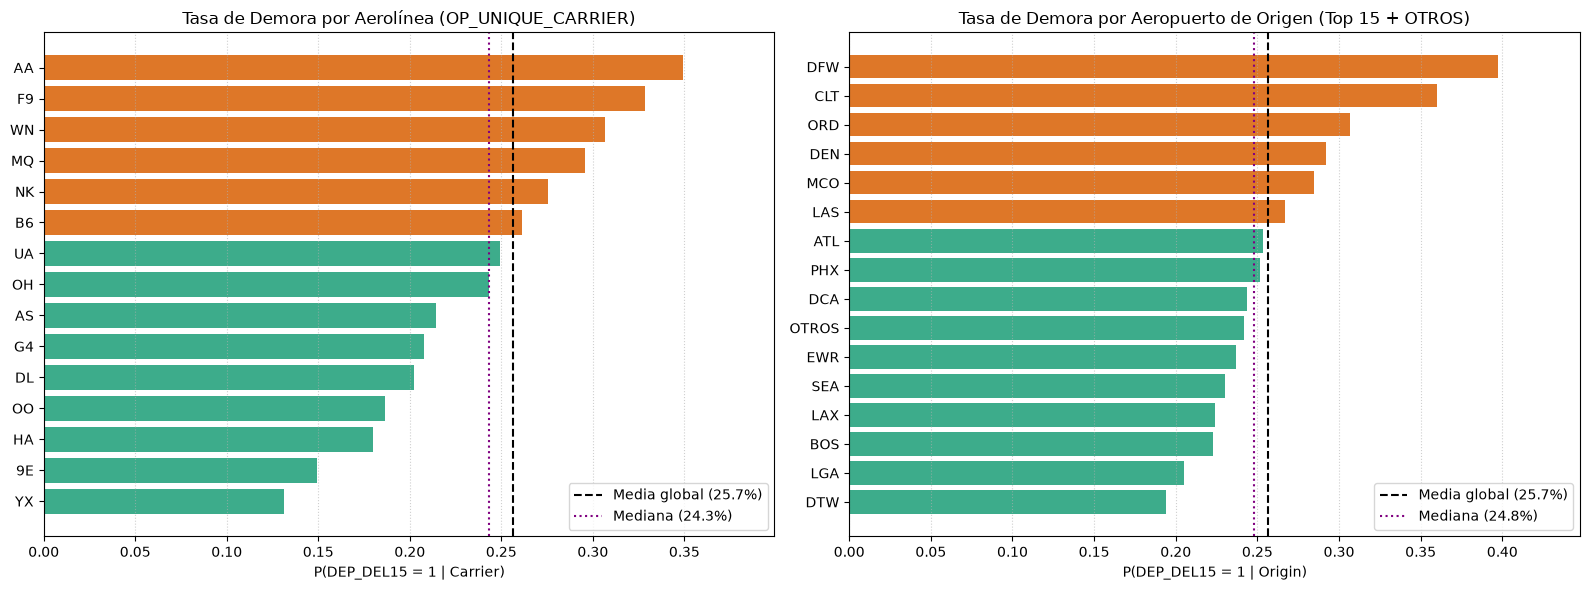

In [51]:
# ==============================================================================
# 3. PANEL VISUAL: GRADIENTES DE PROBABILIDAD CONDICIONAL P(Y=1 | X)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel Izquierdo: Aerolíneas
colores_carrier = ['#d95f02' if p > tasa_base_global else '#1b9e77' for p in ct_carrier[1]]
axes[0].barh(ct_carrier.index, ct_carrier[1], color=colores_carrier, alpha=0.85)
axes[0].axvline(tasa_base_global, color='black', linestyle='--', linewidth=1.5, label=f'Media global ({tasa_base_global*100:.1f}%)')
mediana_carrier = ct_carrier[1].median()
axes[0].axvline(mediana_carrier, color='purple', linestyle=':', linewidth=1.5, label=f'Mediana ({mediana_carrier*100:.1f}%)')
axes[0].set_title('Tasa de Demora por Aerolínea (OP_UNIQUE_CARRIER)')
axes[0].set_xlabel('P(DEP_DEL15 = 1 | Carrier)')
axes[0].set_xlim(0, max(ct_carrier[1]) + 0.05)
axes[0].grid(axis='x', linestyle=':', alpha=0.6)
axes[0].legend(loc='lower right')

# Panel Derecho: Aeropuertos de Origen (Top 15 + OTROS)
colores_origin = ['#d95f02' if p > tasa_base_global else '#1b9e77' for p in ct_origin[1]]
axes[1].barh(ct_origin.index, ct_origin[1], color=colores_origin, alpha=0.85)
axes[1].axvline(tasa_base_global, color='black', linestyle='--', linewidth=1.5, label=f'Media global ({tasa_base_global*100:.1f}%)')
mediana_origin = ct_origin[1].median()
axes[1].axvline(mediana_origin, color='purple', linestyle=':', linewidth=1.5, label=f'Mediana ({mediana_origin*100:.1f}%)')
axes[1].set_title('Tasa de Demora por Aeropuerto de Origen (Top 15 + OTROS)')
axes[1].set_xlabel('P(DEP_DEL15 = 1 | Origin)')
axes[1].set_xlim(0, max(ct_origin[1]) + 0.05)
axes[1].grid(axis='x', linestyle=':', alpha=0.6)
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

# Limpieza de la columna temporal para no conservar en el df
df_processed.drop(columns=['ORIGIN_TOP'], inplace=True)